# 6. Hafta | Kendi Projemin Veri Analizi
## Proje: Müşteri Hizmetlerinde Müşteri Temsilcisi ve Yapay Zekâ Destekli Chatbot Tercihini Etkileyen Faktörler

**Grup:** Bireysel proje  
**Ekip görevleri:** Veri kaynaklarını belirleme, verileri hazırlama, Python ile ortalama hesaplama, grafik hazırlama ve yorumlama.

Bu çalışmada açık erişimli iki anket veri seti (Yatawara vd., 2025; Ramadhani vd., 2025) ve TÜİK'in 2026 Yapay Zekâ İstatistikleri kullanılmıştır. Veri uydurulmamıştır; bütün sayılar dosyalardan hesaplanır.

- **Yatawara veri seti:** Müşterilerin chatbot deneyimini ölçer (chatbot özellikleri, güven, memnuniyet, satın alma niyeti).
- **Ramadhani veri seti:** Bu veri setinde birkaç bölüm var; ben yalnızca **müşteri temsilcisiyle ilgili T1–T7 sorularını** kullandım. Bu sorular müşteri temsilcisinin becerisini, bilgisini, adil davranmasını, dürüstlüğünü, talebe açık olmasını, talebi ciddiye almasını ve güvenilirliğini sorar.
- **TÜİK:** Türkiye'de yaşa göre üretken yapay zekâ kullanım oranı (genel bağlam için).

İki veri setinde de katılımcılara doğrudan “müşteri temsilcisi mi, chatbot mu tercih edersiniz?” diye sorulmadığı için tercih oranı hesaplayamadım. Bu konu literatürle tartışılacaktır.

**Colab'a yüklenecek dosyalar:**  
- `AI Chatbot Affordances and Purchase Intention Dataset.csv` (Yatawara vd., 2025)  
- `HID Impact - Suppl Material - Questionnaire Result Data.csv` (Ramadhani vd., 2025)

In [1]:
import glob
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

# Dosyaları Colab'da soldaki "Dosyalar" panelinden yüklediyseniz bu hücre tekrar sormaz.
# Yüklemediyseniz iki veri dosyasını seçmenizi ister (Colab dışında aynı klasördeki dosyaları kullanır).
def veri_dosyalari():
    return glob.glob("*.csv") + glob.glob("*.xlsx")

def bul(parca):
    # Dosya adındaki boşluk/alt çizgi ve büyük-küçük harf farkı sorun çıkarmasın
    return next((a for a in veri_dosyalari() if parca in a.lower().replace("_", " ")), None)

def hazir_mi():
    return bul("ai chatbot affordances") is not None and bul("hid impact") is not None

if not hazir_mi():
    try:
        from google.colab import files
        files.upload()   # iki veri dosyasını birlikte seçin
    except ImportError:
        pass

if not hazir_mi():
    raise FileNotFoundError("İki veri dosyası bulunamadı. Soldaki Dosyalar panelinden iki CSV dosyasını yükleyip hücreyi tekrar çalıştırın.")

yata_file = bul("ai chatbot affordances")
rama_file = bul("hid impact")

oku = lambda ad: pd.read_excel(ad) if ad.lower().endswith((".xlsx", ".xls")) else pd.read_csv(ad)  # CSV (veya orijinal Excel)
yata = oku(yata_file)
rama = oku(rama_file)
yata.columns = [str(c).strip() for c in yata.columns]
rama.columns = [str(c).strip() for c in rama.columns]

sonuc = Path("sonuc")
sonuc.mkdir(exist_ok=True)
print("Yatawara boyutu (satır, sütun):", yata.shape)
print("Ramadhani boyutu (satır, sütun):", rama.shape)
print("Gözlem birimi: Her satır bir anket katılımcısıdır. Anket maddeleri 1–5 Likert puanıdır.")

Saving AI Chatbot Affordances and Purchase Intention Dataset.csv to AI Chatbot Affordances and Purchase Intention Dataset.csv
Saving HID Impact - Suppl Material - Questionnaire Result Data.csv to HID Impact - Suppl Material - Questionnaire Result Data.csv
Yatawara boyutu (satır, sütun): (385, 38)
Ramadhani boyutu (satır, sütun): (297, 29)
Gözlem birimi: Her satır bir anket katılımcısıdır. Anket maddeleri 1–5 Likert puanıdır.


## A. Veri tanıtımı

| Veri kaynağı | Dosya / veri | Lisans ve erişim | Veri türü ve gözlem sayısı |
|---|---|---|---:|
| Yatawara vd. (2025), Mendeley Data | `AI Chatbot Affordances and Purchase Intention Dataset.csv` | CC BY 4.0; DOI: 10.17632/9fz3rrm3xj.2 (Version 2, 7 Nisan 2025) | CSV anket verisi; 385 katılımcı |
| Ramadhani vd. (2025), Zenodo | `HID Impact - Suppl Material - Questionnaire Result Data.csv` | CC BY 4.0; DOI: 10.5281/zenodo.15745343 (Version v1, 15 Haziran 2025) | CSV anket verisi; 297 katılımcı |
| TÜİK (2026) | Yapay Zekâ İstatistikleri, resmî bülten/grafik | TÜİK kaynak gösterilerek kullanılmalıdır | Yaş ve cinsiyete göre yüzde oranları |

**Erişim tarihi:** 07.11.2026.  
**Dosya biçimi:** Kullanılan iki anket verisi **CSV** (`.csv`, UTF-8) biçimindedir. Mendeley ve Zenodo'daki orijinal dosyalar Excel olduğu için bunları Pandas ile CSV'ye dönüştürdüm; satır, sütun ve değerlerde hiçbir değişiklik yapmadım. TÜİK kaynağı yayımlanmış resmî istatistik grafiğidir.  
**Satır ve sütunların anlamı:** Her satır bir katılımcıdır. Sütunlar yaş, cinsiyet gibi bilgileri ve anket sorularına verilen yanıtları içerir.  
**Ölçü birimi:** Anket soruları 1–5 Likert puanıdır (1 = kesinlikle katılmıyorum, 5 = kesinlikle katılıyorum). TÜİK oranları yüzdedir (%).  
**Verinin niteliği:** Gerçek, açık erişimli ikincil veridir; temsili veri kullanılmamıştır. İki veri seti de CC BY 4.0 lisanslıdır (https://creativecommons.org/licenses/by/4.0/). Veri dosyaları GitHub'da `veri` klasöründe, kaynak ve lisans bilgisiyle paylaşılır; tek değişiklik Excel → CSV biçim dönüşümüdür.
**Ekip üyelerinin görevleri:** Bireysel çalışma; veri bulma, hazırlama, hesaplama, grafik ve yorum bana aittir.

**Ramadhani'de kullandığım sorular (T1–T7, müşteri temsilcisiyle ilgili):**
T1 gerekli becerilere sahip olma, T2 gerekli bilgilere erişebilme, T3 adil davranma, T4 dürüstlük ve bütünlük, T5 müşteri talebine açık olma, T6 talebi ciddiye alma, T7 güvenilir olma.

**Kaynak bağlantıları:**  
- Yatawara vd. (2025): https://data.mendeley.com/datasets/9fz3rrm3xj/2 (Version 2 – güncel sürüm; ilk sürüm 27 Aralık 2024)  
- Ramadhani vd. (2025): https://zenodo.org/records/15745343 (Version v1)  
- TÜİK (2026): https://veriportali.tuik.gov.tr/tr/press/62066

**Proje GitHub deposu:** https://github.com/aysemanav/temsilci-vs-chatbot-tercih-faktorleri

## B. Başlangıç: verilerin Colab'a yüklenmesi ve okunması

Yukarıdaki hücre iki CSV dosyasını Colab'a yükler ve Pandas ile okur. Dosyalar her çalıştırmada yeniden yüklenmelidir.

In [2]:
T = [f"T{i}" for i in range(1, 8)]
display(yata.head())
display(rama[["Age", "Gender"] + T].head())
print("Eksik değer sayısı – Yatawara:", int(yata.isna().sum().sum()))
print("Eksik değer sayısı – Ramadhani (kullandığım T1–T7 soruları):", int(rama[T].isna().sum().sum()))

,CA1,CA2,CA3,CA4,CA5,CA6,CA7,CA8,CA9,CA10,...,PI2,PI3,PI4,PI5,PI6,What is your age?,What is your gender?,Have you ever interacted with an AI-driven chatbot while shopping online?,What is your current employment status?,How often do you shop online?
0,5,5,5,5,4,5,4,4,4,5,...,5,4,4,4,4,18-29 years,Female,Yes,Employed full-time,Monthly
1,4,5,5,4,5,4,4,4,5,4,...,4,5,5,4,5,30-39 years,Male,yes,Employed full-time,A few times a year
2,4,4,4,4,4,3,4,4,4,4,...,5,5,4,4,3,18-29 years,Male,Yes,Student,A few times a year
3,2,5,3,4,3,2,4,4,2,2,...,3,5,5,5,2,40-49 years,Male,yes,Employed full-time,A few times a year
4,4,3,3,3,4,3,4,3,3,4,...,4,4,3,3,3,30-39 years,Male,Yes,Employed full-time,Daily


,Age,Gender,T1,T2,T3,T4,T5,T6,T7
0,13 - 28 years (Generation Z),Female,3,3,3,3,3,3,3
1,13 - 28 years (Generation Z),Female,5,5,5,5,5,5,5
2,13 - 28 years (Generation Z),Male,4,4,4,3,4,5,5
3,13 - 28 years (Generation Z),Female,5,5,4,4,4,3,3
4,13 - 28 years (Generation Z),Female,5,5,4,5,4,5,4


Eksik değer sayısı – Yatawara: 1
Eksik değer sayısı – Ramadhani (kullandığım T1–T7 soruları): 0


## C. Veri inceleme ve hesaplama

Her grup için yanıt sayısı, **toplam puan** ve **ortalama puan** hesaplanır. Puanlar 1–5 arasındadır.

In [3]:
def ozet(df, gruplar):
    satirlar = []
    for ad, sutunlar in gruplar.items():
        d = df[sutunlar].apply(pd.to_numeric, errors="coerce").stack()
        satirlar.append({"Değişken": ad, "Yanıt sayısı": int(d.count()),
                         "Toplam puan": int(d.sum()), "Ortalama (1–5)": round(d.mean(), 2)})
    return pd.DataFrame(satirlar)

# Yatawara: chatbot deneyimi
yata_gruplar = {
    "Chatbot özellikleri (CA)": [f"CA{i}" for i in range(1, 12)],
    "Chatbotla etkileşime bağlılık (CE)": [f"CE{i}" for i in range(1, 6)],
    "Chatbota güven (CT)": [f"CT{i}" for i in range(1, 6)],
    "Chatbot memnuniyeti (CS)": [f"CS{i}" for i in range(1, 7)],
    "Satın alma niyeti (PI)": [f"PI{i}" for i in range(1, 7)],
}
yata_tablo = ozet(yata, yata_gruplar)

# Ramadhani: yalnızca müşteri temsilcisiyle ilgili sorular (T1–T7), her soru ayrı
T_AD = {"T1": "Gerekli becerilere sahip olma", "T2": "Gerekli bilgilere erişebilme", "T3": "Adil davranma",
        "T4": "Dürüstlük ve bütünlük", "T5": "Müşteri talebine açık olma", "T6": "Talebi ciddiye alma",
        "T7": "Güvenilir olma"}
rama_tablo = ozet(rama, {f"{k}: {v}": [k] for k, v in T_AD.items()})
t_hepsi = rama[T].stack()

print("Yatawara – chatbot deneyimi:")
display(yata_tablo)
print("Ramadhani – müşteri temsilcisi soruları (T1–T7):")
display(rama_tablo)
print(f"T1–T7 hepsi birlikte: yanıt sayısı = {int(t_hepsi.count())}, toplam puan = {int(t_hepsi.sum())}, ortalama = {t_hepsi.mean():.2f}")

Yatawara – chatbot deneyimi:


,Değişken,Yanıt sayısı,Toplam puan,Ortalama (1–5)
0,Chatbot özellikleri (CA),4235,16407,3.87
1,Chatbotla etkileşime bağlılık (CE),1925,7172,3.73
2,Chatbota güven (CT),1925,7298,3.79
3,Chatbot memnuniyeti (CS),2310,8958,3.88
4,Satın alma niyeti (PI),2310,9098,3.94


Ramadhani – müşteri temsilcisi soruları (T1–T7):


,Değişken,Yanıt sayısı,Toplam puan,Ortalama (1–5)
0,T1: Gerekli becerilere sahip olma,297,1240,4.18
1,T2: Gerekli bilgilere erişebilme,297,1215,4.09
2,T3: Adil davranma,297,1204,4.05
3,T4: Dürüstlük ve bütünlük,297,1210,4.07
4,T5: Müşteri talebine açık olma,297,1218,4.10
5,T6: Talebi ciddiye alma,297,1223,4.12
6,T7: Güvenilir olma,297,1196,4.03


T1–T7 hepsi birlikte: yanıt sayısı = 2079, toplam puan = 8506, ortalama = 4.09


## D. Grafik ve sonuç dosyaları

Beş grafik hazırlanır: yaş ve cinsiyet dağılımı (Yatawara ve Ramadhani), chatbot, müşteri temsilcisi (T1–T7) ve TÜİK. Yaş-cinsiyet grafiklerinde erkek ve kadın yüzdeleri kendi grupları içindeki dağılımdır. Birimler: anket grafiklerinde 1–5 Likert puanı, TÜİK grafiğinde yüzde (%). Grafikler ve özet tablolar `sonuc` klasörüne kaydedilir.

,Yaş grubu,Toplam (%),Erkek (%),Kadın (%),Katılımcı sayısı (n)
0,18–29,57.4,53.6,63.2,221
1,30–39,27.3,29.6,23.7,105
2,40–49,15.3,16.7,13.2,59


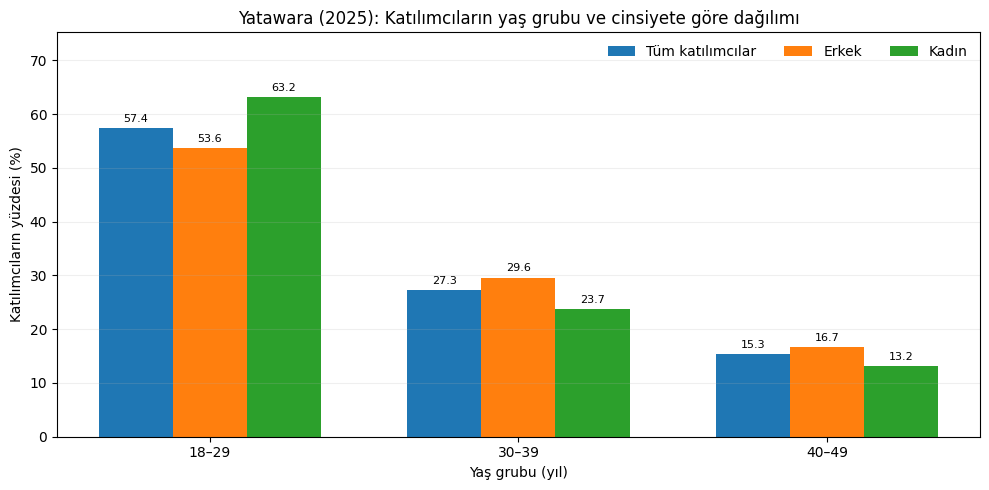

**Grafik 1 açıklaması:** Bu grafik, Yatawara veri setindeki katılımcıların yaş grubuna ve cinsiyete göre dağılımını gösteriyor. Toplam 385 katılımcı var; erkek oranı %60.5, kadın oranı %39.5. En kalabalık yaş grubu 18–29 (%57.4, 221 kişi); en az kişi 40–49 yaş grubunda (59 kişi). Veri setinde 50 yaş ve üzeri katılımcı yok.

,Yaş grubu,Toplam (%),Erkek (%),Kadın (%),Katılımcı sayısı (n)
0,13–28,56.9,53.2,59.5,169
1,29–44,33.7,36.3,31.8,100
2,45–60,8.8,9.7,8.1,26
3,61–79,0.7,0.8,0.6,2


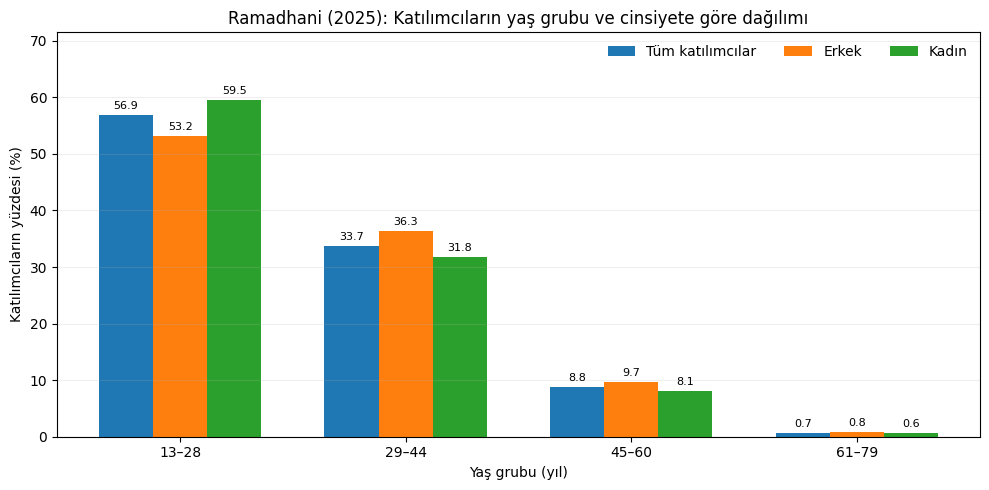

**Grafik 2 açıklaması:** Bu grafik, Ramadhani veri setindeki katılımcıların yaş grubuna ve cinsiyete göre dağılımını gösteriyor. Toplam 297 katılımcı var; erkek oranı %41.8, kadın oranı %58.2. En kalabalık yaş grubu 13–28 (%56.9, 169 kişi); en az kişi 61–79 yaş grubunda (2 kişi). En az kişi olan grupta çok az katılımcı olduğu için o grubun yüzdesi dikkatle okunmalı.

In [4]:
# Grafik 1 ve 2: Katılımcıların yaş grubu ve cinsiyete göre dağılımı
YAS_AD = {"18-29 years": "18–29", "30-39 years": "30–39", "40-49 years": "40–49",
          "13 - 28 years (Generation Z)": "13–28", "29 - 44 years (Millennials)": "29–44",
          "45 - 60 years (Generation X)": "45–60", "61 - 79 years (Baby Boomers)": "61–79"}

def yas_cinsiyet(df, yas_sutunu, cinsiyet_sutunu, yas_sirasi):
    d = df[[yas_sutunu, cinsiyet_sutunu]].dropna().copy()
    d[cinsiyet_sutunu] = d[cinsiyet_sutunu].astype(str).str.strip().replace({"Perempuan": "Female"})
    n = len(d); n_e = (d[cinsiyet_sutunu] == "Male").sum(); n_k = (d[cinsiyet_sutunu] == "Female").sum()
    satirlar = []
    for yas in yas_sirasi:
        g = d[yas_sutunu] == yas
        satirlar.append({"Yaş grubu": YAS_AD[yas],
                         "Toplam (%)": round(g.sum() / n * 100, 1),
                         "Erkek (%)": round((g & (d[cinsiyet_sutunu] == "Male")).sum() / n_e * 100, 1),
                         "Kadın (%)": round((g & (d[cinsiyet_sutunu] == "Female")).sum() / n_k * 100, 1),
                         "Katılımcı sayısı (n)": int(g.sum())})
    tablo = pd.DataFrame(satirlar)
    tablo.attrs.update(n=n, erkek=int(n_e), kadin=int(n_k))
    return tablo

def yas_cinsiyet_grafik(tablo, baslik, xetiket, dosya):
    x = np.arange(len(tablo)); w = 0.24
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, (sutun, ad) in enumerate([("Toplam (%)", "Tüm katılımcılar"), ("Erkek (%)", "Erkek"), ("Kadın (%)", "Kadın")]):
        cubuk = ax.bar(x + (i - 1) * w, tablo[sutun], w, label=ad)
        ax.bar_label(cubuk, fmt="%.1f", padding=3, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(tablo["Yaş grubu"])
    ax.set_xlabel(xetiket); ax.set_ylabel("Katılımcıların yüzdesi (%)")
    ax.set_ylim(0, max(tablo[["Toplam (%)", "Erkek (%)", "Kadın (%)"]].max()) + 12)
    ax.set_title(baslik); ax.legend(ncol=3, frameon=False); ax.grid(axis="y", alpha=.2)
    fig.tight_layout(); fig.savefig(sonuc / dosya, dpi=160); plt.show()

def yas_aciklama(no, tablo, ad, ek):
    n, e, k = tablo.attrs["n"], tablo.attrs["erkek"], tablo.attrs["kadin"]
    bu = tablo.loc[tablo["Katılımcı sayısı (n)"].idxmax()]; az = tablo.loc[tablo["Katılımcı sayısı (n)"].idxmin()]
    return (f"**Grafik {no} açıklaması:** Bu grafik, {ad} veri setindeki katılımcıların yaş grubuna ve cinsiyete göre dağılımını gösteriyor. "
            f"Toplam {n} katılımcı var; erkek oranı %{e/n*100:.1f}, kadın oranı %{k/n*100:.1f}. "
            f"En kalabalık yaş grubu {bu['Yaş grubu']} (%{bu['Toplam (%)']:.1f}, {bu['Katılımcı sayısı (n)']} kişi); en az kişi {az['Yaş grubu']} yaş grubunda ({az['Katılımcı sayısı (n)']} kişi). {ek}")

yata_demo = yas_cinsiyet(yata, "What is your age?", "What is your gender?", ["18-29 years", "30-39 years", "40-49 years"])
rama_demo = yas_cinsiyet(rama, "Age", "Gender", ["13 - 28 years (Generation Z)", "29 - 44 years (Millennials)",
                                                  "45 - 60 years (Generation X)", "61 - 79 years (Baby Boomers)"])

display(yata_demo)
yas_cinsiyet_grafik(yata_demo, "Yatawara (2025): Katılımcıların yaş grubu ve cinsiyete göre dağılımı", "Yaş grubu (yıl)", "grafik1_yatawara_yas_cinsiyet.png")
aciklama_y = yas_aciklama(1, yata_demo, "Yatawara", "Veri setinde 50 yaş ve üzeri katılımcı yok.")
display(Markdown(aciklama_y))

display(rama_demo)
yas_cinsiyet_grafik(rama_demo, "Ramadhani (2025): Katılımcıların yaş grubu ve cinsiyete göre dağılımı", "Yaş grubu (yıl)", "grafik2_ramadhani_yas_cinsiyet.png")
aciklama_r = yas_aciklama(2, rama_demo, "Ramadhani", "En az kişi olan grupta çok az katılımcı olduğu için o grubun yüzdesi dikkatle okunmalı.")
display(Markdown(aciklama_r))

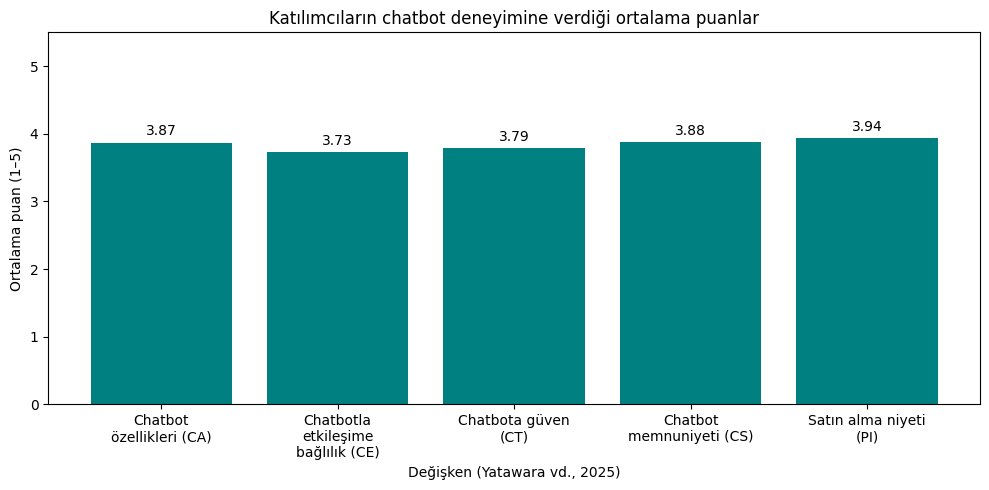

**Grafik 3 açıklaması:** Bu grafik, katılımcıların chatbot deneyimine verdiği ortalama puanları gösteriyor. En yüksek ortalama “Satın alma niyeti (PI)” için (3.94), en düşük ortalama “Chatbotla etkileşime bağlılık (CE)” için (3.73). Bütün ortalamalar 3.73 ile 3.94 arasında, yani orta noktanın (3) üzerinde ama 4'ün altında. Bu grafik sadece chatbotla ilgilidir, müşteri temsilcisiyle karşılaştırma yapmaz.

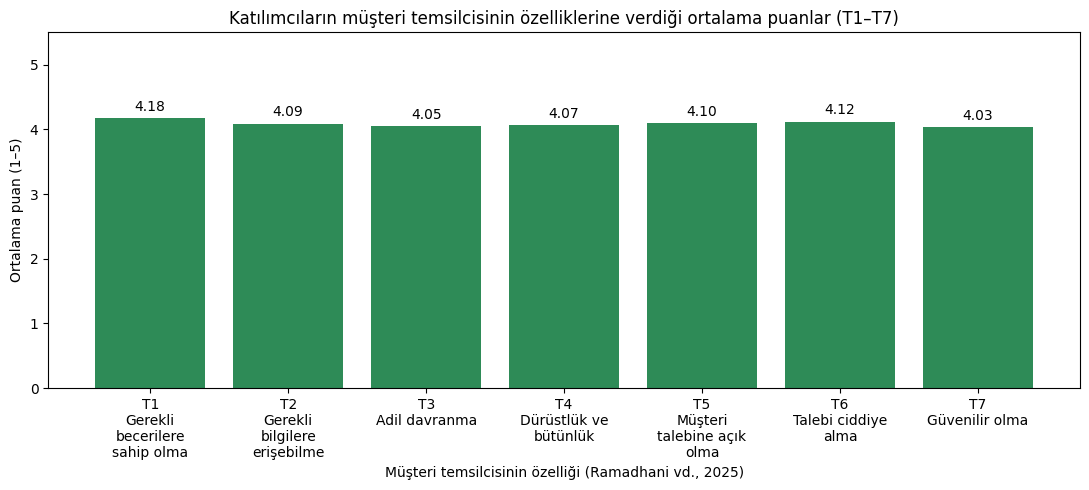

**Grafik 4 açıklaması:** Bu grafik, katılımcıların müşteri temsilcisinin yedi özelliğine verdiği ortalama puanları gösteriyor. En yüksek puan T1: Gerekli becerilere sahip olma (4.18), en düşük puan T7: Güvenilir olma (4.03). Yedi sorunun hepsi 4'ün üzerinde ve birbirine çok yakın (4.03–4.18); yani katılımcılar müşteri temsilcisini bu özelliklerin hepsinde yüksek değerlendirmiş. Bu sorular chatbot için sorulmadığı için chatbotla doğrudan karşılaştırma yapılamaz.

In [5]:
# Grafik 3: Yatawara – chatbot deneyimi
fig, ax = plt.subplots(figsize=(10, 5))
etiket = ["\n".join(textwrap.wrap(a, 18)) for a in yata_tablo["Değişken"]]
cubuk = ax.bar(etiket, yata_tablo["Ortalama (1–5)"], color="teal")
ax.bar_label(cubuk, fmt="%.2f", padding=3)
ax.set_xlabel("Değişken (Yatawara vd., 2025)")
ax.set_ylabel("Ortalama puan (1–5)")
ax.set_ylim(0, 5.5)
ax.set_title("Katılımcıların chatbot deneyimine verdiği ortalama puanlar")
fig.tight_layout(); fig.savefig(sonuc / "grafik3_chatbot.png", dpi=160); plt.show()

y_en = yata_tablo.loc[yata_tablo["Ortalama (1–5)"].idxmax()]
y_az = yata_tablo.loc[yata_tablo["Ortalama (1–5)"].idxmin()]
y_min, y_max = yata_tablo["Ortalama (1–5)"].min(), yata_tablo["Ortalama (1–5)"].max()
aciklama1 = (f"**Grafik 3 açıklaması:** Bu grafik, katılımcıların chatbot deneyimine verdiği ortalama puanları gösteriyor. "
             f"En yüksek ortalama “{y_en['Değişken']}” için ({y_en['Ortalama (1–5)']:.2f}), en düşük ortalama “{y_az['Değişken']}” için ({y_az['Ortalama (1–5)']:.2f}). "
             f"Bütün ortalamalar {y_min:.2f} ile {y_max:.2f} arasında" +
             (", yani orta noktanın (3) üzerinde ama 4'ün altında." if y_min > 3 and y_max < 4 else ".") +
             " Bu grafik sadece chatbotla ilgilidir, müşteri temsilcisiyle karşılaştırma yapmaz.")
display(Markdown(aciklama1))

# Grafik 4: Ramadhani – müşteri temsilcisi soruları (T1–T7)
fig, ax = plt.subplots(figsize=(11, 5))
etiket = [f"{k}\n" + "\n".join(textwrap.wrap(v, 14)) for k, v in T_AD.items()]
cubuk = ax.bar(etiket, rama_tablo["Ortalama (1–5)"], color="seagreen")
ax.bar_label(cubuk, fmt="%.2f", padding=3)
ax.set_xlabel("Müşteri temsilcisinin özelliği (Ramadhani vd., 2025)")
ax.set_ylabel("Ortalama puan (1–5)")
ax.set_ylim(0, 5.5)
ax.set_title("Katılımcıların müşteri temsilcisinin özelliklerine verdiği ortalama puanlar (T1–T7)")
fig.tight_layout(); fig.savefig(sonuc / "grafik4_musteri_temsilcisi_T1_T7.png", dpi=160); plt.show()

t_en = rama_tablo.loc[rama_tablo["Ortalama (1–5)"].idxmax()]
t_az = rama_tablo.loc[rama_tablo["Ortalama (1–5)"].idxmin()]
t_min, t_max = rama_tablo["Ortalama (1–5)"].min(), rama_tablo["Ortalama (1–5)"].max()
aciklama2 = (f"**Grafik 4 açıklaması:** Bu grafik, katılımcıların müşteri temsilcisinin yedi özelliğine verdiği ortalama puanları gösteriyor. "
             f"En yüksek puan {t_en['Değişken']} ({t_en['Ortalama (1–5)']:.2f}), en düşük puan {t_az['Değişken']} ({t_az['Ortalama (1–5)']:.2f}). " +
             (f"Yedi sorunun hepsi 4'ün üzerinde ve birbirine çok yakın ({t_min:.2f}–{t_max:.2f}); yani katılımcılar müşteri temsilcisini bu özelliklerin hepsinde yüksek değerlendirmiş. "
              if t_min > 4 else f"Ortalamalar {t_min:.2f} ile {t_max:.2f} arasında. ") +
             "Bu sorular chatbot için sorulmadığı için chatbotla doğrudan karşılaştırma yapılamaz.")
display(Markdown(aciklama2))

,Yaş grubu,Toplam,Erkek,Kadın
0,Toplam,37.6,37.2,38.1
1,16-24,64.9,61.6,68.4
2,25-34,55.7,54.4,57.1
3,35-44,38.1,39.6,36.6
4,45-54,20.6,21.6,19.5
5,55-64,10.6,11.5,9.7
6,65-74,5.1,5.3,4.9


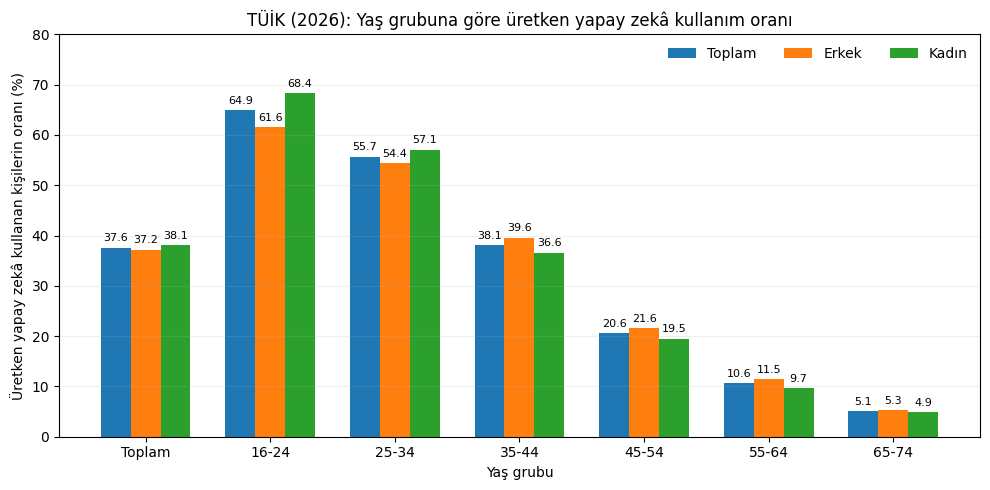

**Grafik 5 açıklaması:** Bu grafik, Türkiye'de üretken yapay zekâ kullanan kişilerin oranını yaş grubuna göre gösteriyor. Genel oran %37.6; en yüksek oran 16-24 yaşında (%64.9), en düşük oran 65-74 yaşında (%5.1). Yaş büyüdükçe kullanım oranı düşüyor. Bu grafik genel yapay zekâ kullanımını gösterir, müşteri hizmetlerindeki tercihi ölçmez.

In [6]:
# Grafik 5: TÜİK – yaşa göre üretken yapay zekâ kullanımı
tuik = pd.DataFrame({
    "Yaş grubu": ["Toplam", "16-24", "25-34", "35-44", "45-54", "55-64", "65-74"],
    "Toplam": [37.6, 64.9, 55.7, 38.1, 20.6, 10.6, 5.1],
    "Erkek": [37.2, 61.6, 54.4, 39.6, 21.6, 11.5, 5.3],
    "Kadın": [38.1, 68.4, 57.1, 36.6, 19.5, 9.7, 4.9],
})
display(tuik)
x = np.arange(len(tuik)); w = .24
fig, ax = plt.subplots(figsize=(10, 5))
for i, sutun in enumerate(["Toplam", "Erkek", "Kadın"]):
    cubuk = ax.bar(x + (i - 1) * w, tuik[sutun], w, label=sutun)
    ax.bar_label(cubuk, fmt="%.1f", padding=3, fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(tuik["Yaş grubu"])
ax.set_xlabel("Yaş grubu")
ax.set_ylabel("Üretken yapay zekâ kullanan kişilerin oranı (%)")
ax.set_title("TÜİK (2026): Yaş grubuna göre üretken yapay zekâ kullanım oranı")
ax.legend(ncol=3, frameon=False); ax.set_ylim(0, 80); ax.grid(axis="y", alpha=.2)
fig.tight_layout(); fig.savefig(sonuc / "grafik5_tuik.png", dpi=160); plt.show()

yas = tuik.iloc[1:]
u_en = yas.loc[yas["Toplam"].idxmax()]; u_az = yas.loc[yas["Toplam"].idxmin()]
aciklama3 = (f"**Grafik 5 açıklaması:** Bu grafik, Türkiye'de üretken yapay zekâ kullanan kişilerin oranını yaş grubuna göre gösteriyor. "
             f"Genel oran %{tuik.iloc[0]['Toplam']:.1f}; en yüksek oran {u_en['Yaş grubu']} yaşında (%{u_en['Toplam']:.1f}), en düşük oran {u_az['Yaş grubu']} yaşında (%{u_az['Toplam']:.1f}). " +
             ("Yaş büyüdükçe kullanım oranı düşüyor. " if yas["Toplam"].is_monotonic_decreasing else "") +
             "Bu grafik genel yapay zekâ kullanımını gösterir, müşteri hizmetlerindeki tercihi ölçmez.")
display(Markdown(aciklama3))

## E. Akademik yorum

In [7]:
ct = yata_tablo.loc[yata_tablo["Değişken"].str.contains("güven"), "Ortalama (1–5)"].iloc[0]
yorum = f"""
**Veri kaynağı ve değişken:** Yatawara vd. (2025) ve Ramadhani vd. (2025) anket verilerinde chatbot deneyimini ve müşteri temsilcisiyle ilgili T1–T7 sorularını, TÜİK (2026) verisinde yaşa göre yapay zekâ kullanımını inceledim.

**Toplam / ortalama ve birimler:** Anket puanları 1–5 arasındadır (Likert); chatbota güven ortalaması {ct:.2f}, T1–T7 ortalaması {t_hepsi.mean():.2f} ({int(t_hepsi.count())} yanıt, toplam puan {int(t_hepsi.sum())}), TÜİK değerleri yüzdedir (%).

**Grafikte görülen bulgu:** Chatbot ortalamaları {y_min:.2f}–{y_max:.2f}, müşteri temsilcisi ortalamaları {t_min:.2f}–{t_max:.2f} arasında; ama bunlar farklı kişilere ve farklı sorulara ait olduğu için birbiriyle karşılaştırmadım.

**Sınırlılıklar ve ölçemediği şeyler:** Hiçbir veri setinde “temsilci mi, chatbot mu?” sorusu olmadığı için tercih oranı hesaplayamadım, veriler Türkiye'de toplanmadı ve ortalamalar bir şeyin başka bir şeye neden olduğunu kanıtlamaz.

**Ekipçe yapılan işlem:** Bireysel çalıştığım için veriyi bulma, hesaplama, grafik hazırlama ve yorumlamayı ben yaptım.

**Kaynaklar**
- Yatawara, K. vd. (2025). *AI Chatbot Affordances and Purchase Intention Dataset*. Mendeley Data, Version 2 (7 Nisan 2025; ilk sürüm 27 Aralık 2024). https://doi.org/10.17632/9fz3rrm3xj.2 (CC BY 4.0)
- Ramadhani, A. P., Luhukay, D. ve Lindrianasari. (2025). *Dataset of AI in customer service: The impact of human involvement disclosure on customer trust and communication style with hybrid agent services in e-commerce*. Zenodo, Version v1 (15 Haziran 2025). https://doi.org/10.5281/zenodo.15745343 (CC BY 4.0)
- Türkiye İstatistik Kurumu. (2026). *Yapay Zekâ İstatistikleri, 2026*. https://veriportali.tuik.gov.tr/tr/press/62066
"""
display(Markdown(yorum))


**Veri kaynağı ve değişken:** Yatawara vd. (2025) ve Ramadhani vd. (2025) anket verilerinde chatbot deneyimini ve müşteri temsilcisiyle ilgili T1–T7 sorularını, TÜİK (2026) verisinde yaşa göre yapay zekâ kullanımını inceledim.

**Toplam / ortalama ve birimler:** Anket puanları 1–5 arasındadır (Likert); chatbota güven ortalaması 3.79, T1–T7 ortalaması 4.09 (2079 yanıt, toplam puan 8506), TÜİK değerleri yüzdedir (%).

**Grafikte görülen bulgu:** Chatbot ortalamaları 3.73–3.94, müşteri temsilcisi ortalamaları 4.03–4.18 arasında; ama bunlar farklı kişilere ve farklı sorulara ait olduğu için birbiriyle karşılaştırmadım.

**Sınırlılıklar ve ölçemediği şeyler:** Hiçbir veri setinde “temsilci mi, chatbot mu?” sorusu olmadığı için tercih oranı hesaplayamadım, veriler Türkiye'de toplanmadı ve ortalamalar bir şeyin başka bir şeye neden olduğunu kanıtlamaz.

**Ekipçe yapılan işlem:** Bireysel çalıştığım için veriyi bulma, hesaplama, grafik hazırlama ve yorumlamayı ben yaptım.

**Kaynaklar**
- Yatawara, K. vd. (2025). *AI Chatbot Affordances and Purchase Intention Dataset*. Mendeley Data, Version 2 (7 Nisan 2025; ilk sürüm 27 Aralık 2024). https://doi.org/10.17632/9fz3rrm3xj.2 (CC BY 4.0)
- Ramadhani, A. P., Luhukay, D. ve Lindrianasari. (2025). *Dataset of AI in customer service: The impact of human involvement disclosure on customer trust and communication style with hybrid agent services in e-commerce*. Zenodo, Version v1 (15 Haziran 2025). https://doi.org/10.5281/zenodo.15745343 (CC BY 4.0)
- Türkiye İstatistik Kurumu. (2026). *Yapay Zekâ İstatistikleri, 2026*. https://veriportali.tuik.gov.tr/tr/press/62066


### Görev paylaşımı

| Görev | Kim yaptı |
|---|---|
| Veri kaynaklarını bulma, lisans ve kişisel veri kontrolü | Bireysel çalışma (ben) |
| Verileri CSV'ye çevirme ve hazırlama | Bireysel çalışma (ben) |
| Toplam/ortalama hesapları ve grafikler | Bireysel çalışma (ben) |
| Yorum yazma, README ve GitHub'a yükleme | Bireysel çalışma (ben) |

In [8]:
# Sonuçları CSV ve PNG olarak sakla (ham veri değil, yalnızca özet)
import shutil

ozet = pd.DataFrame([
    {"metrik": "Yatawara katılımcı sayısı", "deger": len(yata)},
    {"metrik": "Ramadhani katılımcı sayısı", "deger": len(rama)},
    {"metrik": "Chatbota güven ortalaması (1–5 puan)", "deger": round(ct, 2)},
    {"metrik": "Müşteri temsilcisi T1–T7 ortalaması (1–5 puan)", "deger": round(t_hepsi.mean(), 2)},
    {"metrik": "Müşteri temsilcisi T1–T7 toplam puan", "deger": int(t_hepsi.sum())},
    {"metrik": "Müşteri temsilcisi T1–T7 yanıt sayısı", "deger": int(t_hepsi.count())},
], dtype=object)
ozet.to_csv(sonuc / "ozet.csv", index=False, encoding="utf-8-sig")

yata_tablo.to_csv(sonuc / "Yatawara_Chatbot_Ortalamalari.csv", index=False, encoding="utf-8-sig")
rama_tablo.to_csv(sonuc / "Ramadhani_Musteri_Temsilcisi_T1_T7.csv", index=False, encoding="utf-8-sig")
tuik.to_csv(sonuc / "TUIK_2026_Yas_Cinsiyet.csv", index=False, encoding="utf-8-sig")
yata_demo.to_csv(sonuc / "Yatawara_Yas_Cinsiyet.csv", index=False, encoding="utf-8-sig")
rama_demo.to_csv(sonuc / "Ramadhani_Yas_Cinsiyet.csv", index=False, encoding="utf-8-sig")
with open(sonuc / "grafik_aciklamalari.md", "w", encoding="utf-8") as f:
    f.write("\n\n".join([aciklama_y, aciklama_r, aciklama1, aciklama2, aciklama3, yorum]))

print("Kaydedilen dosyalar:", sorted(p.name for p in sonuc.iterdir()))
zip_yolu = shutil.make_archive("hafta6_sonuclar", "zip", "sonuc")
print("İndirilebilir ZIP:", zip_yolu, "(Dosyalar panelinden indirebilirsiniz)")

Kaydedilen dosyalar: ['Ramadhani_Musteri_Temsilcisi_T1_T7.csv', 'Ramadhani_Yas_Cinsiyet.csv', 'TUIK_2026_Yas_Cinsiyet.csv', 'Yatawara_Chatbot_Ortalamalari.csv', 'Yatawara_Yas_Cinsiyet.csv', 'grafik1_yatawara_yas_cinsiyet.png', 'grafik2_ramadhani_yas_cinsiyet.png', 'grafik3_chatbot.png', 'grafik4_musteri_temsilcisi_T1_T7.png', 'grafik5_tuik.png', 'grafik_aciklamalari.md', 'ozet.csv']
İndirilebilir ZIP: /content/hafta6_sonuclar.zip (Dosyalar panelinden indirebilirsiniz)
